In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [14]:
%pip install ucimlrepo

In [15]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
car_evaluation = fetch_ucirepo(id=222)

# extract features and targets
X = car_evaluation.data.features
y = car_evaluation.data.targets

# combine them into a single pandas DataFrame
df = X.copy()
df['class'] = y

# view the dataframe
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,class
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  class        45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [17]:
df.drop(columns=["contact","poutcome"],axis=1,inplace=True)

In [18]:
df.isnull().sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
day_of_week,0
month,0


In [19]:
null_col = ["job","education"]
for col in null_col:
    df[col].fillna(df[col].mode()[0],inplace=True)

In [20]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
day_of_week,0
month,0


In [21]:
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [48]:
x_col = df.drop(columns=["class"],axis=1)
y_col = df["class"]

In [26]:
num_col = x_col.select_dtypes(include=np.number).columns
cat_col = x_col.select_dtypes(exclude=np.number).columns

In [27]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
for col in cat_col:
    df[col] = oe.fit_transform(df[[col]])

In [31]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])

In [32]:
df.describe()

,age,job,marital,education,default,balance,housing,loan,day_of_week,month,duration,campaign,pdays,previous,class
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,4.276061,1.167725,1.142664,0.018027,1362.272058,0.555838,0.160226,15.806419,5.523014,258.163080,2.763841,40.197828,0.580323,0.116985
std,10.618762,3.239553,0.608230,0.652218,0.133049,3044.765829,0.496878,0.366820,8.322476,3.006911,257.527812,3.098021,100.128746,2.303441,0.321406
min,18.000000,0.000000,0.000000,0.000000,0.000000,-8019.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,1.000000,1.000000,1.000000,0.000000,72.000000,0.000000,0.000000,8.000000,3.000000,103.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,4.000000,1.000000,1.000000,0.000000,448.000000,1.000000,0.000000,16.000000,6.000000,180.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,7.000000,2.000000,2.000000,0.000000,1428.000000,1.000000,0.000000,21.000000,8.000000,319.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,10.000000,2.000000,2.000000,1.000000,102127.000000,1.000000,1.000000,31.000000,11.000000,4918.000000,63.000000,871.000000,275.000000,1.000000


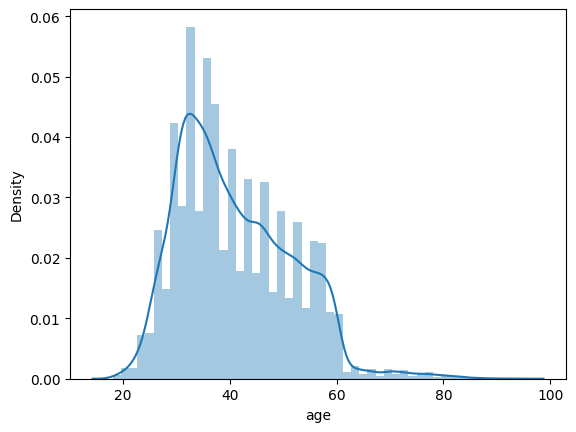

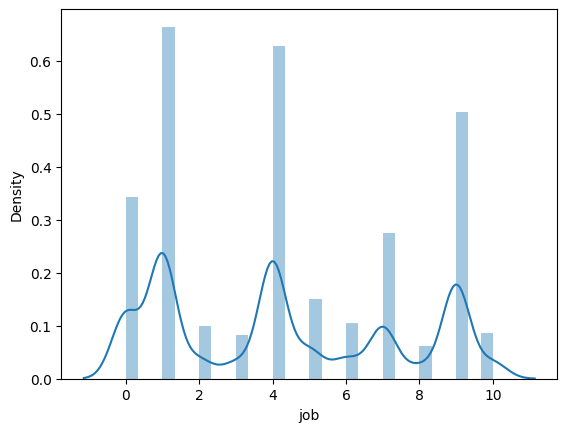

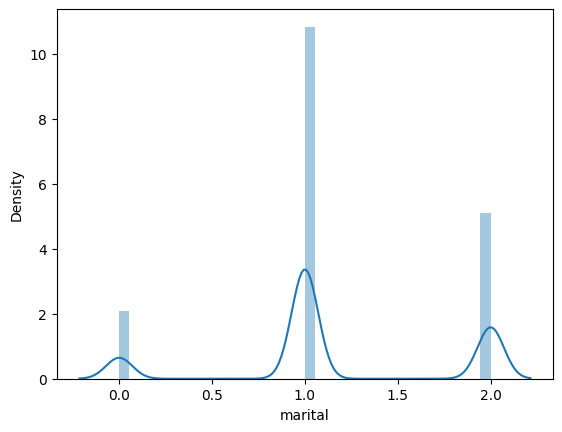

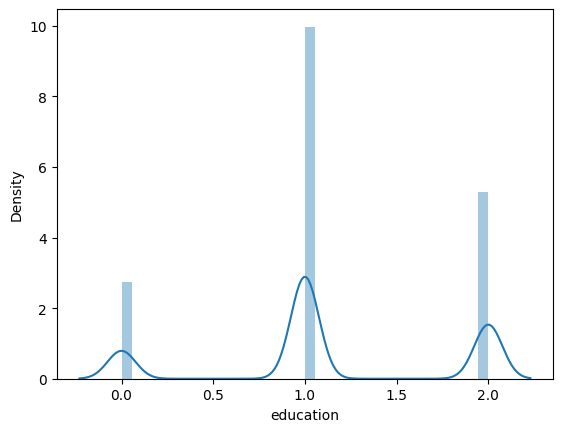

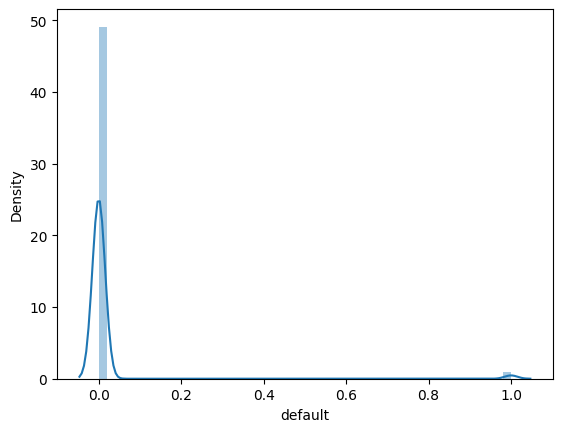

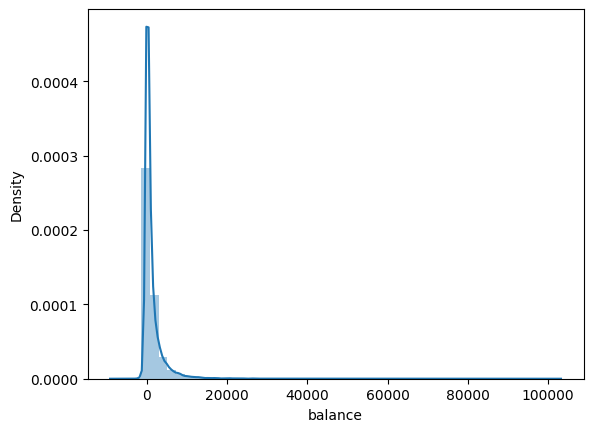

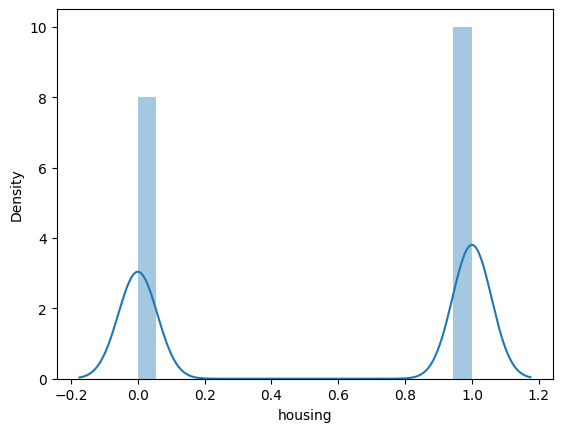

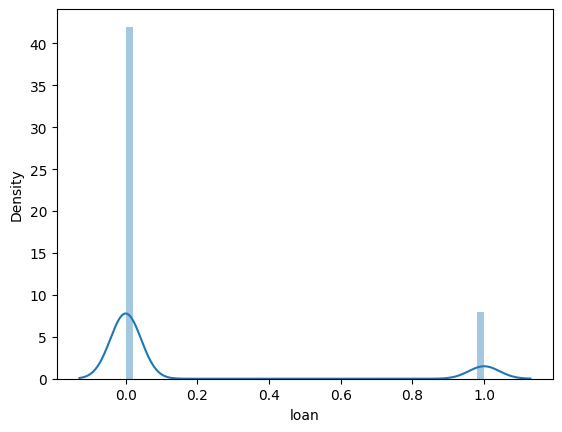

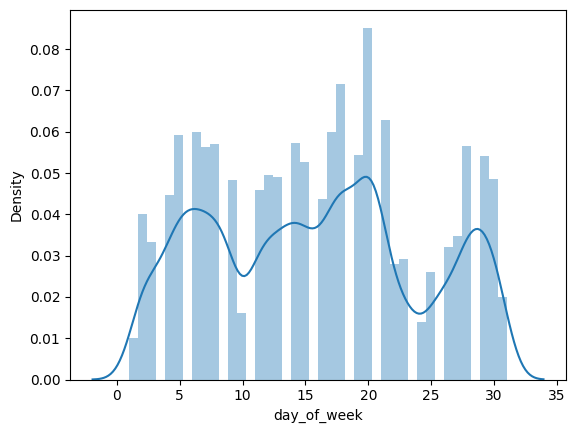

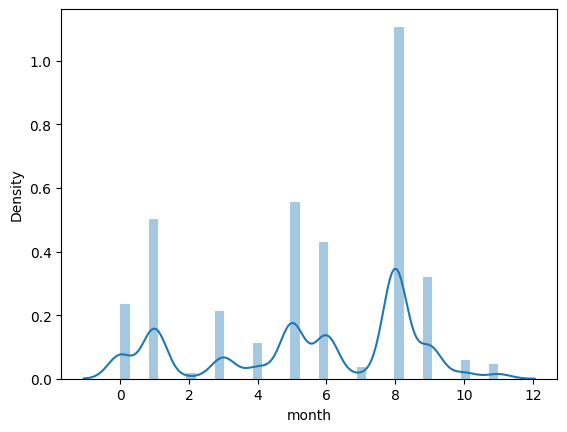

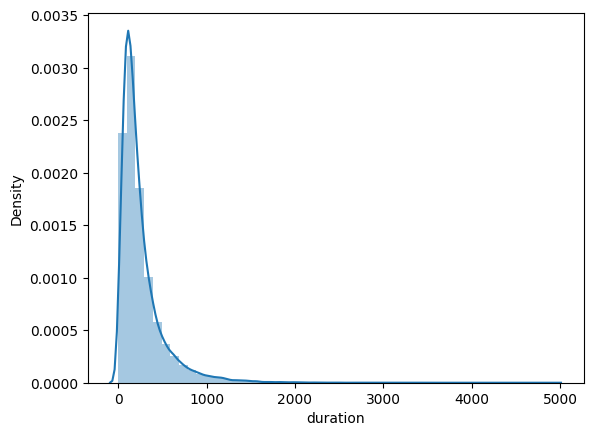

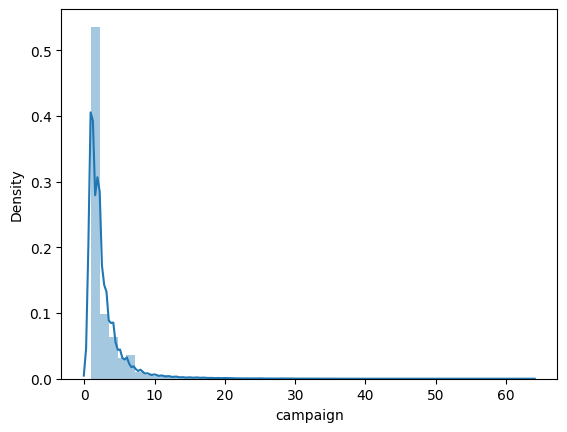

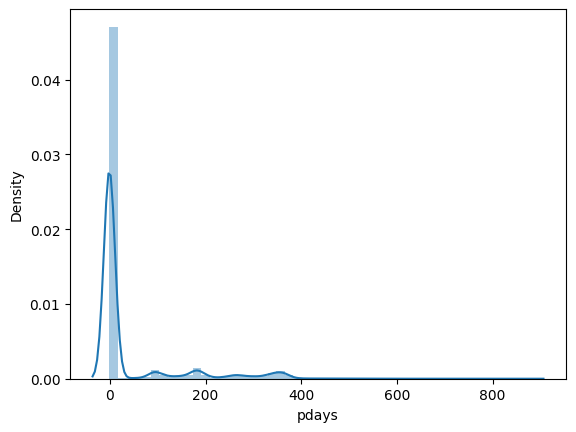

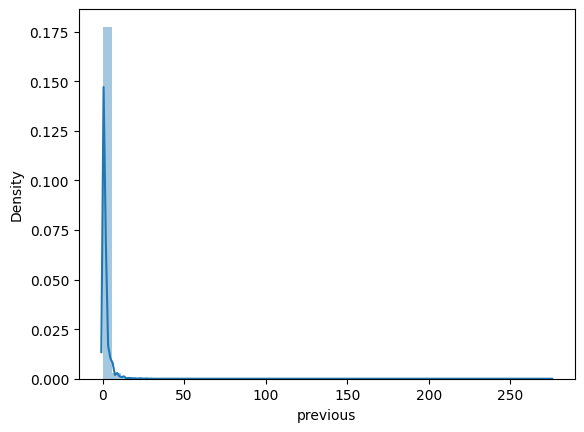

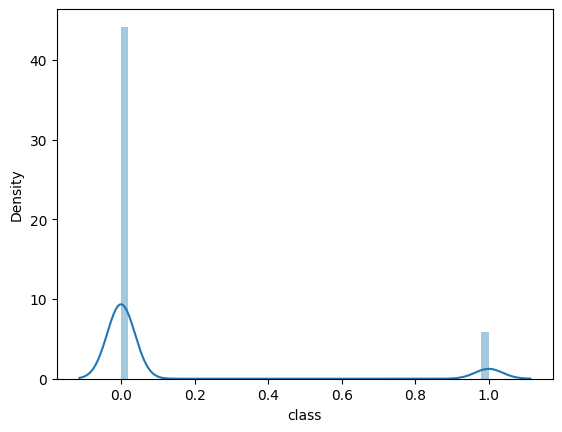

In [33]:
for col in df.columns:
  sns.distplot(df[col])
  plt.show()

In [35]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'day_of_week', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'class'],
      dtype='object')

In [37]:
skweness = ['age','default','balance','duration', 'campaign','pdays','previous']
for col in skweness:
    df[col] = np.log1p(df[col])

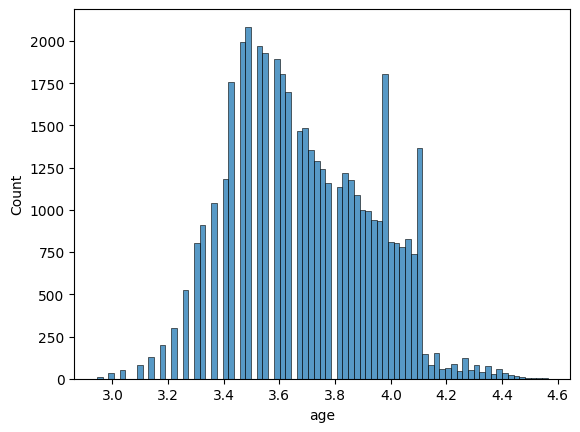

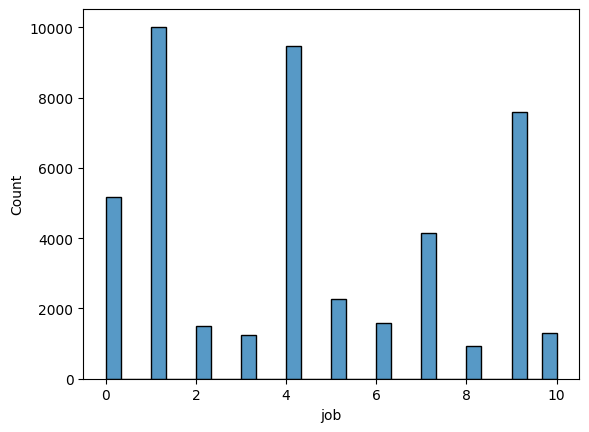

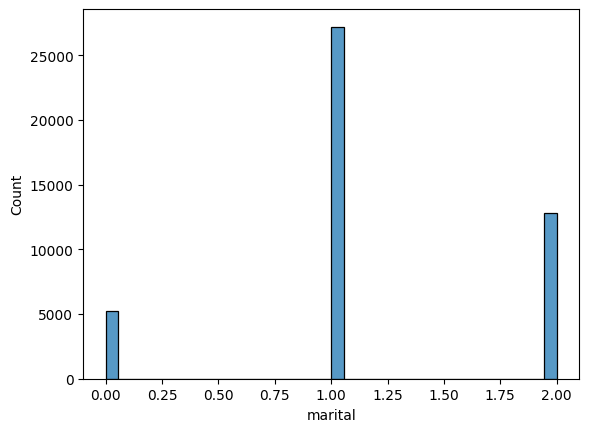

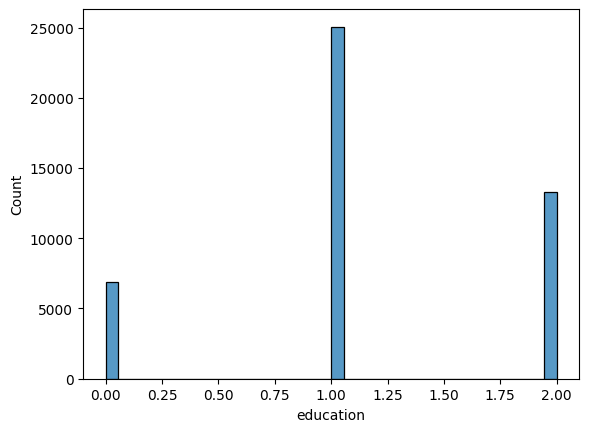

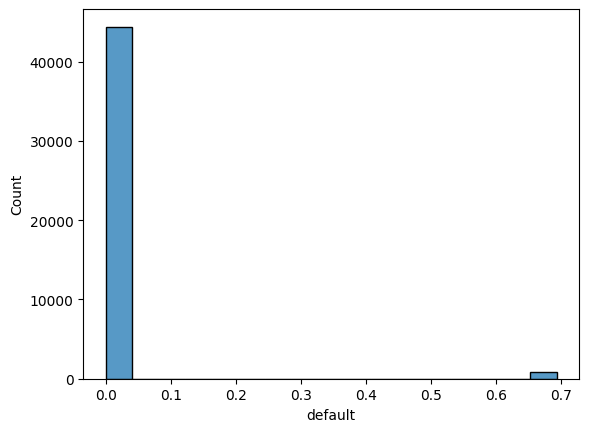

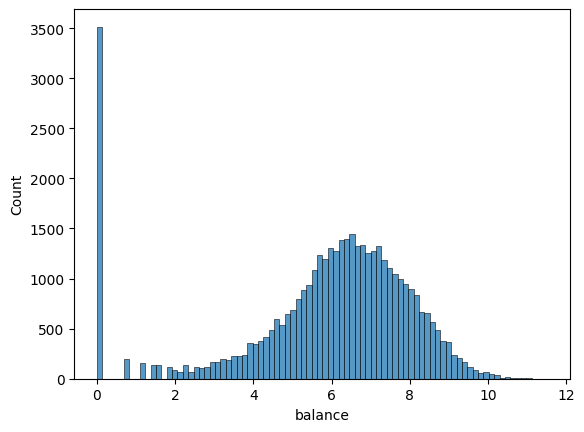

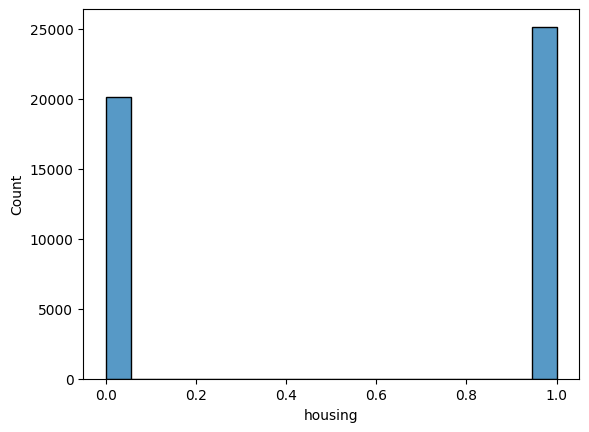

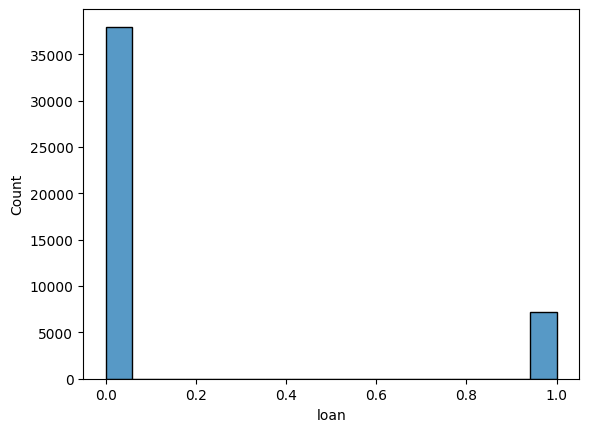

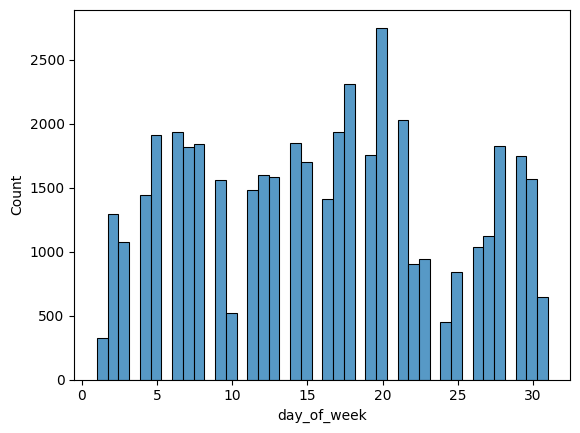

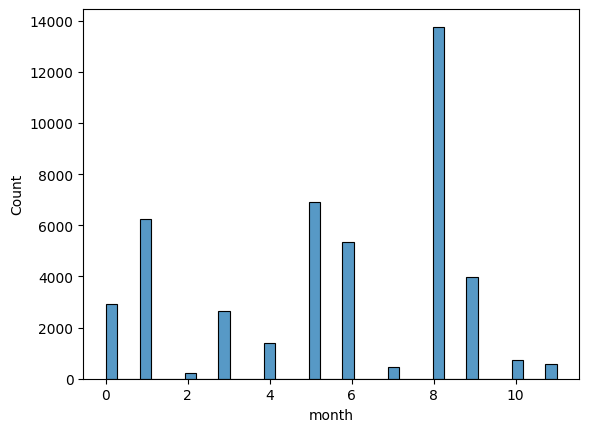

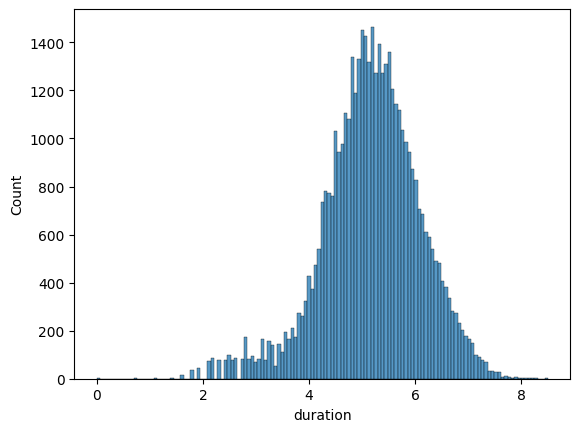

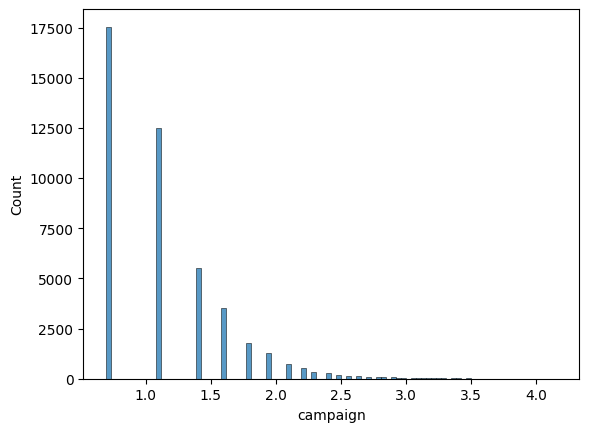

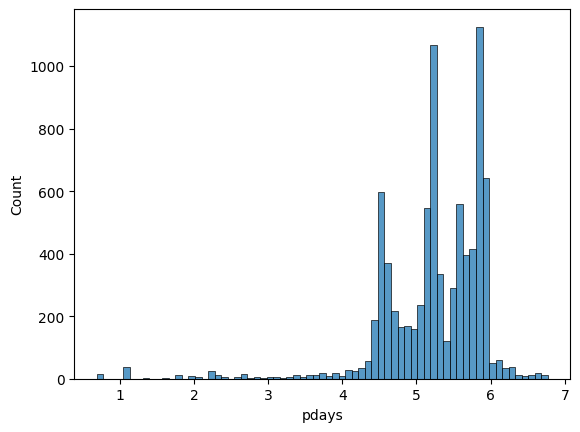

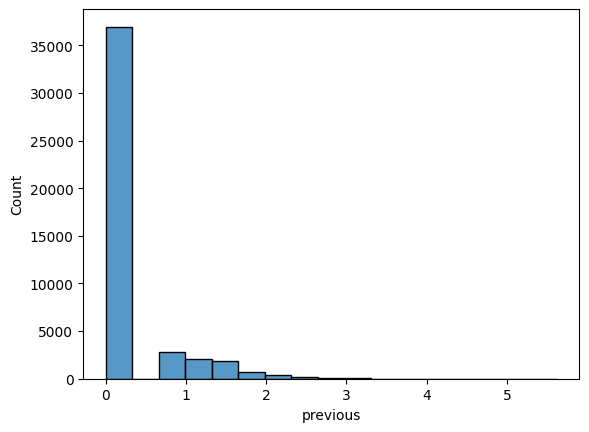

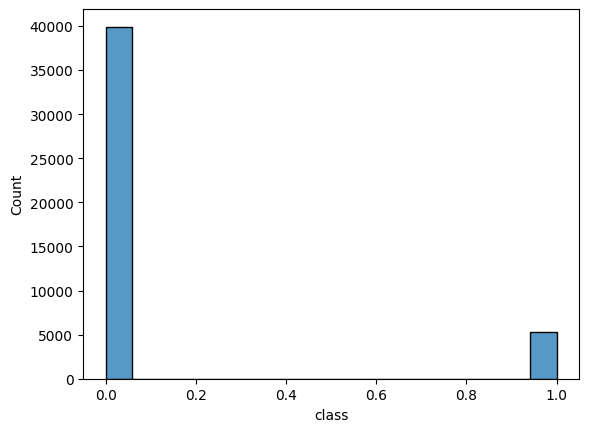

In [39]:
for col in df.columns:
  sns.histplot(df[col])
  plt.show()

In [40]:
%pip install -q outlier-tool-shashikant

In [49]:
from outlier_tool import Outliers
o = Outliers(x_col)

In [50]:
o.find()

,column,method,lower,upper,outliers,percent
0,age,iqr,2.978171,4.440010,53,0.12
1,job,iqr,-8.000000,16.000000,0,0.00
2,marital,iqr,-0.500000,3.500000,0,0.00
3,education,iqr,-0.500000,3.500000,0,0.00
4,default,iqr,0.000000,0.000000,815,1.80
5,balance,iqr,1.397073,10.961163,4060,8.98
6,housing,iqr,-1.500000,2.500000,0,0.00
7,loan,iqr,0.000000,0.000000,7244,16.02
8,day_of_week,iqr,-11.500000,40.500000,0,0.00
9,month,iqr,-4.500000,15.500000,0,0.00


In [51]:
df1 = o.iqr_cap()

In [59]:
# Replace -inf and inf values with NaN so fillna can handle them
df1 = df1.replace([np.inf, -np.inf], np.nan)

# Fill NaN values in the 'balance' column with its mean
df1['balance'] = df1['balance'].fillna(df1['balance'].mean())

# Fill any other remaining NaNs across the dataframe to ensure Adaboost works
df1 = df1.fillna(df1.mean())

In [60]:
X = df1
Y = y_col

In [61]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42, stratify=Y)

In [62]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

ada = AdaBoostClassifier()
ada.fit(x_train,y_train)
y_pred = ada.predict(x_test)

accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy {accuracy}")

cr = classification_report(y_test,y_pred)
print(f"Classifiaction Report {cr}")

train = ada.score(x_train,y_train)
print(f"Train Score {train}")

test = ada.score(x_test,y_test)
print(f"Test Score {test}")

Accuracy 0.8904124737365918
Classifiaction Report               precision    recall  f1-score   support

           0       0.91      0.97      0.94      7985
           1       0.57      0.25      0.35      1058

    accuracy                           0.89      9043
   macro avg       0.74      0.61      0.65      9043
weighted avg       0.87      0.89      0.87      9043

Train Score 0.8919210351692104
Test Score 0.8904124737365918
